# Lista 6

## Pandas and scikit - learn

(6pkt + 2pkt)

Na liście znajdują się 4 zadania. WYkonaj zadanie 1, 2 i wybrane zadanie nr 3 (są dwa zadania nr 3 :) ) Po rozwiązaniu zadaniań pokaż kod prowadzącemu i odpowiedz na **pytanie kontrolne** — tylko wtedy przyznajemy punkty. Dodatkowo prześlij zadanie na platformie skos.

Zadanie domowe oznaczone jest 🏠. Za wykonanie zadania otrzymasz 2pkt.

Korzystamy z danych z poprzedniego wykładu: `./data/student_exam_scores.csv` oraz dziennika sesji nauki `./data/study_sessions.csv`.


In [1]:
import numpy as np
import pandas as pd
import os, sys, glob, shutil, subprocess

DATA_PATH = "./data/student_exam_scores.csv"

# Pobranie danych z Kaggle (tylko za pierwszym razem): https://www.kaggle.com/datasets/saadaliyaseen/analyzing-student-academic-trends
if not os.path.exists(DATA_PATH):
    try:
        import kagglehub
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", "kagglehub"]
        )
        import kagglehub
    folder = kagglehub.dataset_download(
        "saadaliyaseen/analyzing-student-academic-trends"
    )
    csv_file = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)[0]
    os.makedirs("./data", exist_ok=True)
    shutil.copy(csv_file, DATA_PATH)
    print("Pobrano:", os.path.basename(csv_file), "->", DATA_PATH)

LOG_PATH = "./data/study_sessions.csv"

if not os.path.exists(LOG_PATH):
    rng = np.random.default_rng(42)
    students = pd.read_csv(DATA_PATH)
    n_sessions = np.maximum(
        1, (students["hours_studied"] * rng.uniform(40, 60, len(students))).round()
    ).astype(int)
    sid = np.repeat(students["student_id"].to_numpy(), n_sessions)
    sleep = np.repeat(students["sleep_hours"].to_numpy(), n_sessions)
    n = len(sid)
    p_night = np.clip((8 - sleep) / 4, 0.05, 0.8)
    night = rng.random(n) < p_night
    hour = np.where(night, rng.choice([22, 23, 0, 1, 2, 3], n), rng.integers(8, 22, n))
    day = pd.to_datetime("2025-10-01") + pd.to_timedelta(
        rng.integers(0, 120, n), unit="D"
    )
    start = (
        day
        + pd.to_timedelta(hour, unit="h")
        + pd.to_timedelta(rng.integers(0, 60, n), unit="min")
    )
    log = pd.DataFrame(
        {
            "student_id": sid,
            "start_time": start,
            "subject": rng.choice(
                ["math", "physics", "programming", "statistics"],
                n,
                p=[0.35, 0.2, 0.3, 0.15],
            ),
            "duration_min": rng.gamma(3, 15, n).round().astype(int) + 5,
        }
    ).sort_values("start_time")
    log.insert(0, "session_id", np.arange(n))
    log.to_csv(LOG_PATH, index=False)

print("OK")

OK


#### Zadanie 1 — LLM wygenerował Ci kod, teraz potrzebujesz czegoś podobnego

Model językowy napisał dla Ciebie działający kod. Chwilę później potrzebujesz **podobnej**, ale nie identycznej analizy.
Pisanie nowego prompta i sprawdzanie nowej odpowiedzi trwałoby dłużej niż zmiana kilku znaków — więc przerabiasz kod sam.

Dla każdego fragmentu:

1. uruchom kod wygenerowany przez LLM i upewnij się, że rozumiesz, co robi każda linia,
2. skopiuj go do komórki poniżej i **przekształć** zgodnie z poleceniem,
3. staraj się zmienić **jak najmniej** — zwykle wystarczy podmienić argument, dodać jedną metodę albo zamienić funkcję na inną.

Każdy fragment zaczyna się od wczytania danych od nowa, więc fragmenty nie wpływają na siebie nawzajem.


**Fragment 1.** Prompt: _„Dodaj do sessions kolumnę subject_pl z polską nazwą przedmiotu.”_


In [2]:
# wczytanie danych
sessions = pd.read_csv(LOG_PATH, parse_dates=["start_time"])

# kod wygenerowany przez LLM
nazwy = {
    "math": "matematyka",
    "physics": "fizyka",
    "programming": "programowanie",
    "statistics": "statystyka",
}
sessions["subject_pl"] = sessions["subject"].map(nazwy)
sessions[["subject", "subject_pl"]].head()

,subject,subject_pl
0,programming,programowanie
1,statistics,statystyka
2,statistics,statystyka
3,physics,fizyka
4,math,matematyka


**Przekształć:** Zamiast polskiej nazwy dodaj kolumnę `room` z numerem sali, w której odbywają się konsultacje:
matematyka — `'A-101'`, fizyka — `'B-204'`, programowanie — `'C-012'`.
Statystyka **nie ma** sali — w jej wierszach ma się pojawić napis `'online'` (a nie `NaN`).
Na końcu wyświetl, ile sesji przypada na każdą salę.


In [3]:
# Fragment 1 — przekształcony kod
sessions = pd.read_csv(LOG_PATH, parse_dates=["start_time"])

sale = {
    "math": "A-101",
    "physics": "B-204",
    "programming": "C-012",
}  # nie dopisuj statystyki
sessions["room"] = sessions["subject"].map(sale).fillna("online")
sessions["room"].value_counts()

room
A-101     22132
C-012     19076
B-204     12616
online     9488
Name: count, dtype: int64

**Fragment 2.** Prompt: _„Dodaj kolumnę sleep_cat: 'short' gdy student śpi mniej niż 6 h, w przeciwnym razie 'ok'.”_


In [4]:
# wczytanie danych
df = pd.read_csv(DATA_PATH)

# kod wygenerowany przez LLM
df["sleep_cat"] = df["sleep_hours"].apply(lambda h: "short" if h < 6 else "ok")
df["sleep_cat"].value_counts()

sleep_cat
ok       125
short     75
Name: count, dtype: int64

**Przekształć:** Dodaj kolumnę `risk`: `'high'`, gdy student śpi mniej niż 6 h **i jednocześnie** ma frekwencję
(`attendance_percent`) poniżej 70%, w przeciwnym razie `'low'`.
Reguła zależy teraz od **dwóch kolumn** — zastanów się, co trzeba zmienić w wywołaniu `apply`.


In [5]:
# Fragment 2 — przekształcony kod
df = pd.read_csv(DATA_PATH)

# apply na całym DataFrame z axis=1 — lambda dostaje cały wiersz
df["risk"] = df.apply(
    lambda r: (
        "high" if r["sleep_hours"] < 6 and r["attendance_percent"] < 70 else "low"
    ),
    axis=1,
)
df["risk"].value_counts()

risk
low     171
high     29
Name: count, dtype: int64

**Fragment 3.** Prompt: _„Ile minut łącznie trwały sesje z każdego przedmiotu? Posortuj malejąco.”_


In [6]:
# wczytanie danych
sessions = pd.read_csv(LOG_PATH, parse_dates=["start_time"])

# kod wygenerowany przez LLM
sessions.groupby("subject")["duration_min"].sum().sort_values(ascending=False)

subject
math           1105809
programming     954487
physics         633156
statistics      473959
Name: duration_min, dtype: int64

**Przekształć:** Policz **średnią** długość sesji dla każdej pary **student × przedmiot**.
Wynik pokaż jako tabelę: wiersze — `student_id`, kolumny — przedmioty (brak sesji -> `0`).
Wyświetl tylko 5 pierwszych studentów.


In [7]:
# Fragment 3 — przekształcony kod
sessions = pd.read_csv(LOG_PATH, parse_dates=["start_time"])

sessions.groupby(["student_id", "subject"])["duration_min"].mean().unstack(
    fill_value=0
).head()

subject,math,physics,programming,statistics
student_id,,,,
S001,49.718391,46.366337,52.099099,54.982759
S002,54.583333,45.300000,55.090909,54.142857
S003,50.984848,49.208333,52.500000,54.837838
S004,52.968750,50.209302,52.000000,46.468750
S005,47.753425,44.931507,49.176991,46.489796


**Fragment 4.** Prompt: _„Plik z sesjami jest duży. Wczytaj go w kawałkach po 5000 wierszy i policz łączny czas nauki każdego przedmiotu.”_


In [8]:
# kod wygenerowany przez LLM
czesci = []
with pd.read_csv(
    LOG_PATH, chunksize=5000, usecols=["subject", "duration_min"]
) as reader:
    for chunk in reader:
        czesci.append(chunk.groupby("subject")["duration_min"].sum())

pd.concat(czesci).groupby(level=0).sum()

subject
math           1105809
physics         633156
programming     954487
statistics      473959
Name: duration_min, dtype: int64

**Przekształć:** Nadal czytając plik w kawałkach, policz **średnią długość sesji** każdego **studenta**.
Uwaga: średnia średnich z kawałków nie jest poprawną średnią — wynik musi być dokładnie taki sam,
jak przy wczytaniu całego pliku naraz (sprawdź to w ostatniej linii).


In [9]:
# Fragment 4 — przekształcony kod
# zbieramy sumę i liczbę sesji z każdego kawałka, średnią liczymy dopiero na końcu
czesci = []
with pd.read_csv(
    LOG_PATH, chunksize=5000, usecols=["student_id", "duration_min"]
) as reader:
    for chunk in reader:
        czesci.append(chunk.groupby("student_id")["duration_min"].agg(["sum", "count"]))

agg = pd.concat(czesci).groupby(level=0).sum()
srednie = agg["sum"] / agg["count"]

# sprawdzenie z wczytaniem całego pliku naraz
np.allclose(srednie, pd.read_csv(LOG_PATH).groupby("student_id")["duration_min"].mean())

True

**Fragment 5.** Prompt: _„Narysuj, ile minut łącznie uczyli się wszyscy studenci w każdym tygodniu.”_


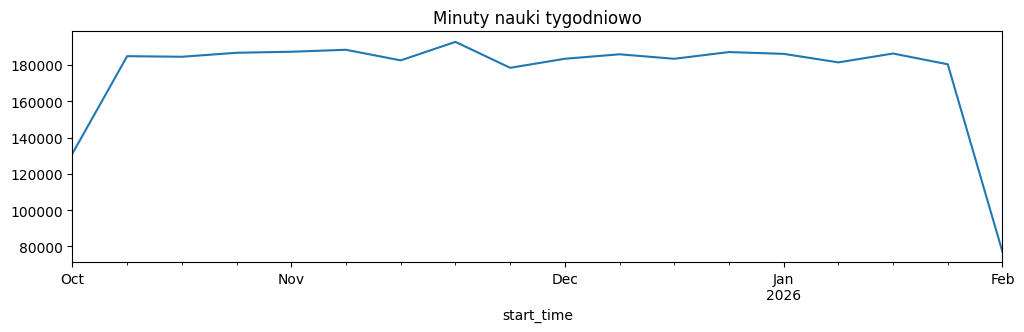

In [ ]:
# wczytanie danych
sessions = pd.read_csv(LOG_PATH, parse_dates=["start_time"])

# kod wygenerowany przez LLM
ts = sessions.set_index("start_time").sort_index()
tygodniowo = ts["duration_min"].resample("W").sum()
tygodniowo.plot(figsize=(12, 3), title="Minuty nauki tygodniowo")

**Przekształć:** Narysuj **miesięczny** czas nauki, ale **osobno dla każdego przedmiotu** — jedna linia na przedmiot.
Czas podaj w **godzinach**, nie w minutach.


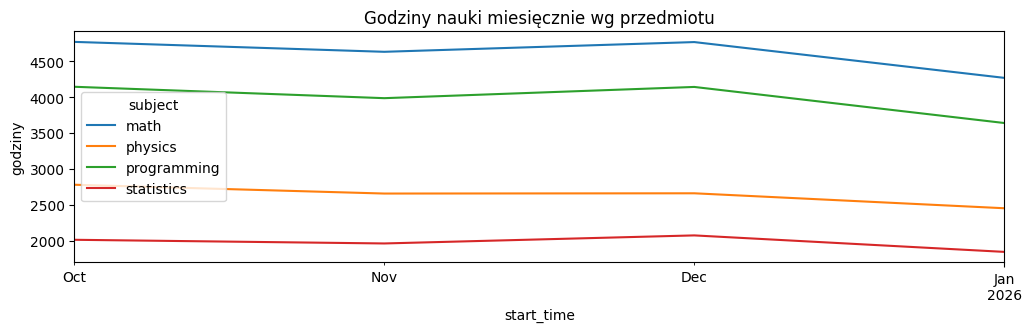

In [ ]:
# Fragment 5 — przekształcony kod
sessions = pd.read_csv(LOG_PATH, parse_dates=["start_time"])

ts = sessions.set_index("start_time").sort_index()
miesiecznie = (
    ts.groupby("subject")["duration_min"].resample("MS").sum().unstack(level=0) / 60
)
miesiecznie.plot(
    figsize=(12, 3), title="Godziny nauki miesięcznie wg przedmiotu", ylabel="godziny"
)

#### Zadanie 2 — Regresja liniowa

Wygeneruj sztuczny zbiór danych regresyjnych za pomocą funkcji `make_regression(n_samples=200, n_features=1, noise=10)`. Następnie podziel dane na zbiór treningowy i testowy (`train_test_split`) i wykonaj regresję. Policz błędy modelu na zbiorze testowym.

Który z modeli regresji daje najlepsze wyniki? Porównaj trzy modele z wykładu.


MAE  (Mean Absolute Error): 8.02
MSE  (Mean Squared Error): 109.39


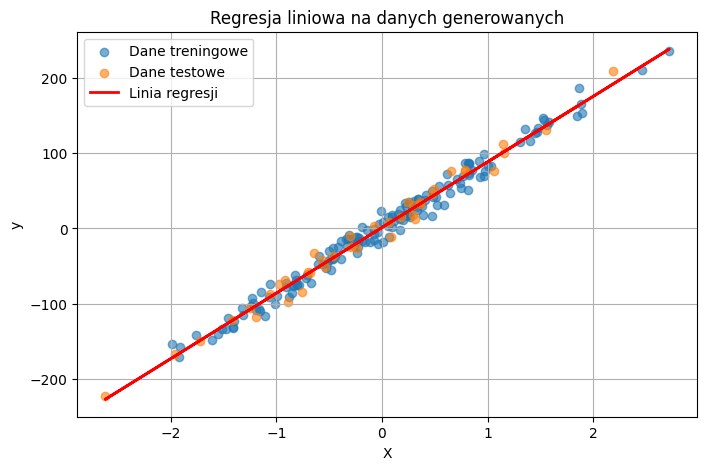

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.datasets import make_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Generowanie danych
X, y = make_regression(n_samples=200, n_features=1, noise=10, random_state=42)

# 2. Podział danych
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Model regresji liniowej (LinearRegression)
model = LinearRegression()
model.fit(X_train, y_train)

# 4. Predykcje
y_pred = model.predict(X_test)

# 5. Błędy regresji
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print("MAE  (Mean Absolute Error):", round(mae, 2))
print("MSE  (Mean Squared Error):", round(mse, 2))

# 6. Wykres: dane + linia regresji
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.6, label="Dane treningowe")
plt.scatter(X_test, y_test, alpha=0.6, label="Dane testowe")
plt.plot(X, model.predict(X), color="red", linewidth=2, label="Linia regresji")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresja liniowa na danych generowanych")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
# Porównanie trzech modeli regresji liniowej: zwykła, Ridge (L2), Lasso (L1)
from sklearn.linear_model import Ridge, Lasso

modele = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0),
}

wyniki = []
for nazwa, m in modele.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    wyniki.append(
        {
            "model": nazwa,
            "MAE": mean_absolute_error(y_test, p),
            "MSE": mean_squared_error(y_test, p),
            "R2": r2_score(y_test, p),
        }
    )

pd.DataFrame(wyniki).set_index("model").round(3)

,MAE,MSE,R2
model,,,
LinearRegression,8.020,109.387,0.985
Ridge,7.952,111.106,0.985
Lasso,7.942,113.210,0.985


#### Zadanie 3 — Porównanie metod klastrowania

Celem zadania jest **porównanie różnych metod klasteryzacji** na prostych zbiorach danych.
Aby to umożliwić, przygotowano **trzy przykładowe datasety**, zróżnicowane pod względem struktury i trudności zadania:

1. **`blobs`** – zbiór punktów pogrupowanych w wyraźnie rozdzielone klastry (w miarę „idealny” przypadek klasteryzacji).
2. **`moons`** – dane w kształcie dwóch półksiężyców, które tworzą nieliniową strukturę i są trudniejsze dla metod zakładających kuliste klastry.
3. **`circles`** – dane w kształcie dwóch koncentrycznych okręgów, trudne do analizy dla algorytmów bazujących na odległości euklidesowej.

Twoim zadaniem jest **przetestowanie kilku metod klasteryzacji** na każdym z datasetów, a następnie **porównanie wyników wizualnie** – czyli na wykresach przedstawiających pogrupowane punkty.

---

##### Metody klasteryzacji do przetestowania

**KMeans**

Parametr: `n_clusters` – liczba oczekiwanych klastrów.

**DBSCAN**

Parametry:

- `eps` – maksymalna odległość między punktami, aby zostały uznane za należące do tego samego klastra;
- `min_samples` – minimalna liczba punktów w sąsiedztwie, aby uznać grupę za klaster.

**Agglomerative Clustering**

Parametr: `n_clusters` – liczba oczekiwanych klastrów.

**Gaussian Mixture Model (GMM)**

Parametr: `n_components` (odpowiednik liczby klastrów).

**Spectral Clustering**

Parametr: `n_clusters`.

##### Zadanie do wykonania

Przygotuj dane. W tym celu wykorzystaj `StandardScaler()`.

Następnie dla każdego z trzech datasetów:

- zastosuj wszystkie podane metody klasteryzacji,
- do przewidywania predykcji skorzystaj z metody `fit_predict`, która zwróci od razu predyk
- dobierz parametry tak, aby uzyskać możliwie sensowny podział,
- narysuj wyniki klasteryzacji na wykresach.

Która metoda sprawdza się najlepiej dla każdego z trzech datasetów?

Możesz brać pod uwagę:

- kształt klastrów,
- obecność szumu,
- poprawność wykrycia struktur widocznych na wykresie,
- wrażliwość metody na parametry.


c:\Users\Barte\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Nie można odnaleźć określonego pliku
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Barte\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Barte\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Barte\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File 

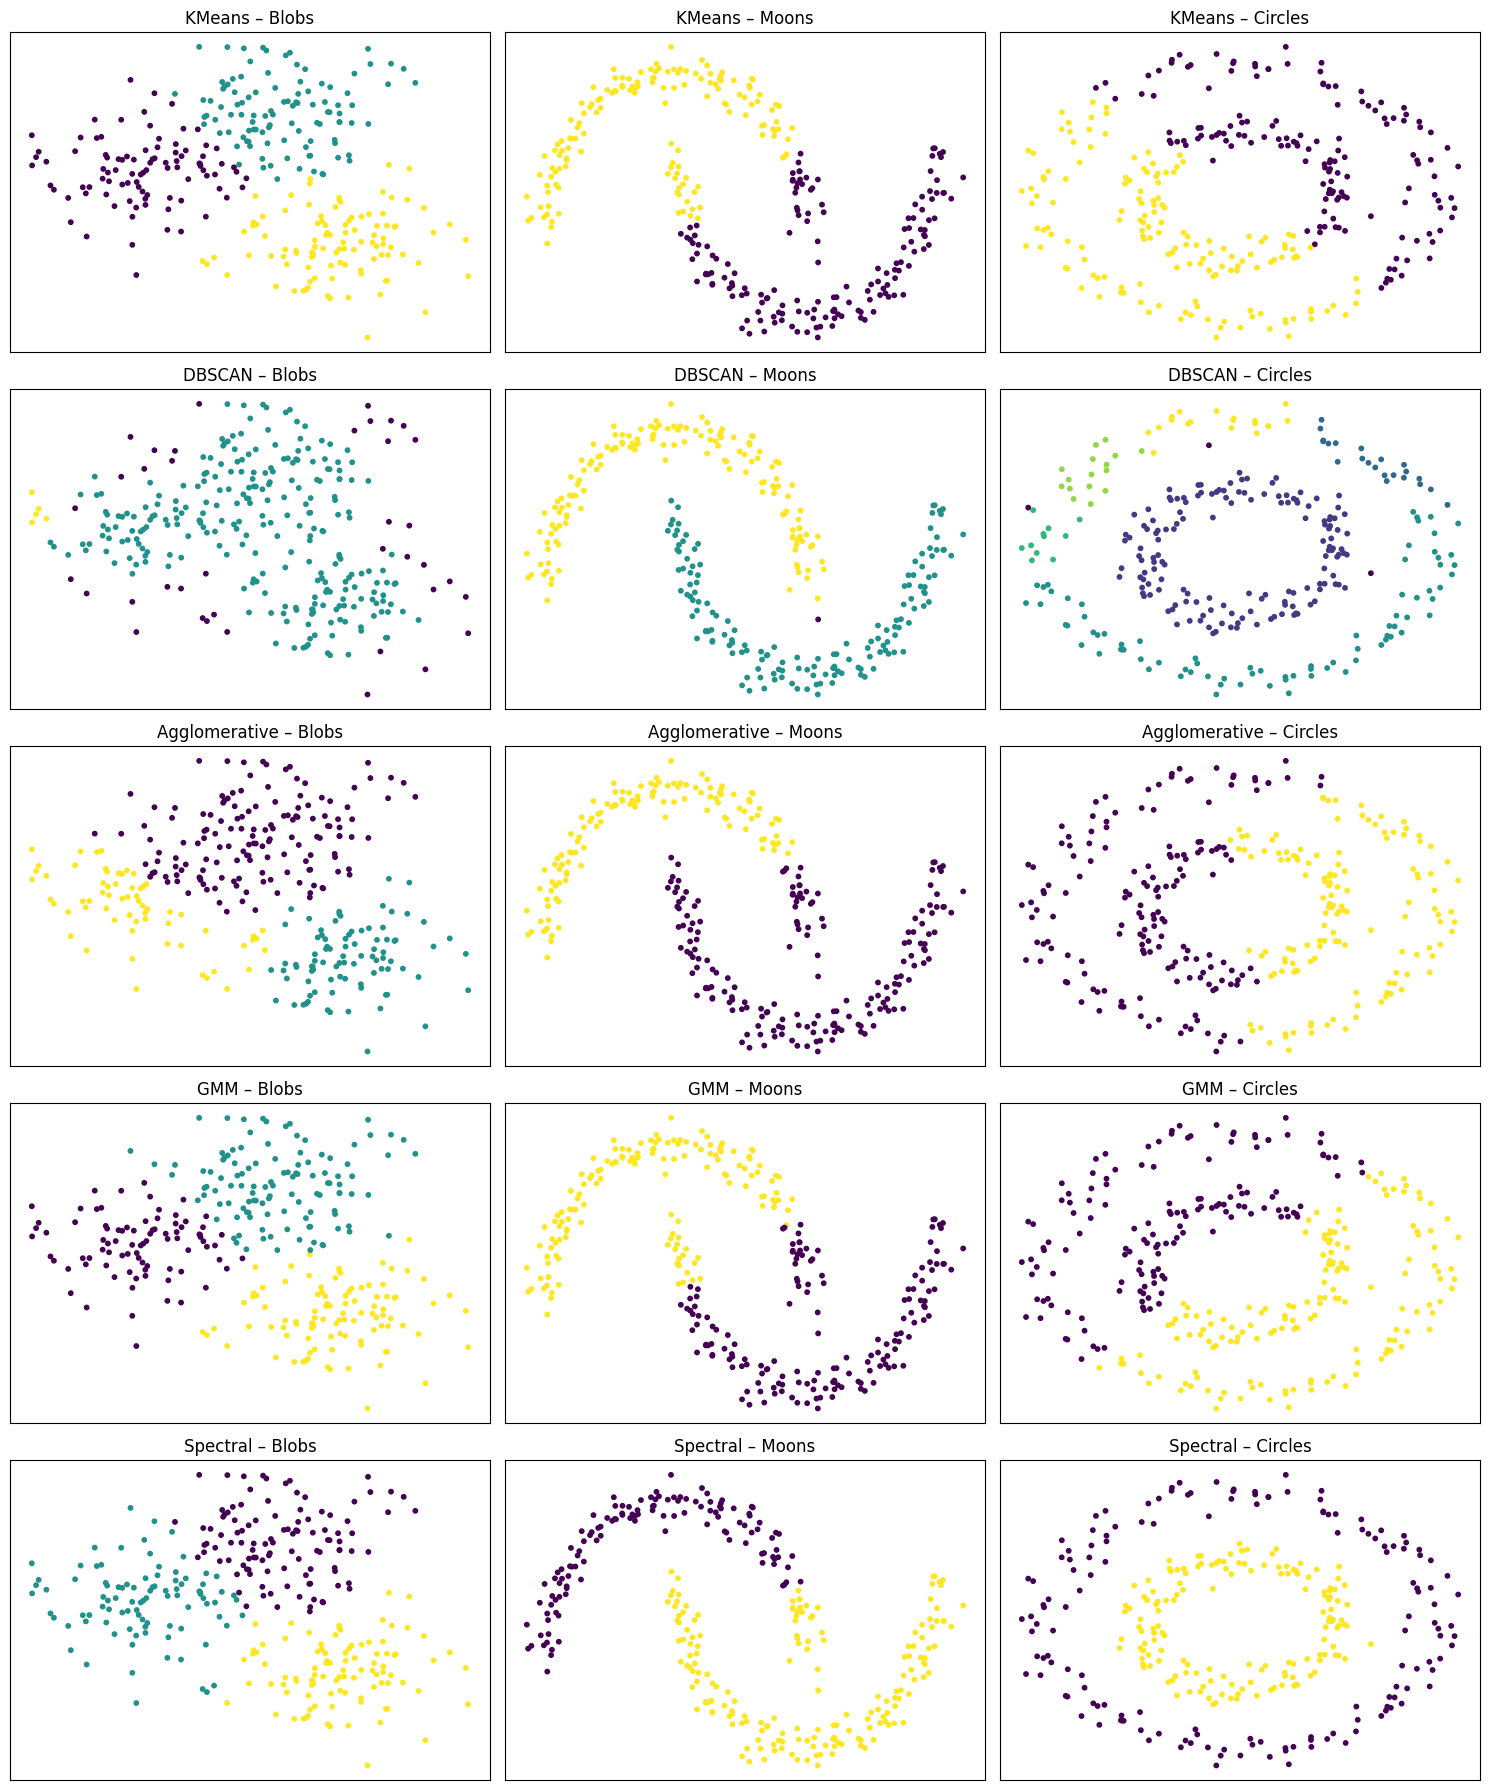

In [14]:
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

# --- 1. Datasets ---
blobs_X, _ = datasets.make_blobs(n_samples=300, centers=3, random_state=0)
moons_X, _ = datasets.make_moons(n_samples=300, noise=0.07, random_state=0)
circles_X, _ = datasets.make_circles(
    n_samples=300, noise=0.07, factor=0.5, random_state=0
)

datasets_list = [("Blobs", blobs_X), ("Moons", moons_X), ("Circles", circles_X)]

# parametry dobrane osobno dla każdego zbioru
params = {
    "Blobs": {"k": 3, "eps": 0.3, "min_samples": 5},
    "Moons": {"k": 2, "eps": 0.3, "min_samples": 5},
    "Circles": {"k": 2, "eps": 0.3, "min_samples": 5},
}

methods = ["KMeans", "DBSCAN", "Agglomerative", "GMM", "Spectral"]

plt.figure(figsize=(15, 18))

for col_idx, (ds_name, X) in enumerate(datasets_list):
    p = params[ds_name]
    standardscaler = StandardScaler()
    X_scaled = standardscaler.fit_transform(X)

    # Przygotowanie etykiet metod
    # --- KMeans ---
    kmeans = KMeans(n_clusters=p["k"], n_init=10, random_state=0)
    kmeans_labels = kmeans.fit_predict(X_scaled)

    # --- DBSCAN ---
    dbscan = DBSCAN(eps=p["eps"], min_samples=p["min_samples"])
    dbscan_labels = dbscan.fit_predict(X_scaled)

    # --- Agglomerative ---
    agg = AgglomerativeClustering(n_clusters=p["k"])
    agg_labels = agg.fit_predict(X_scaled)

    # --- GMM ---
    gmm = GaussianMixture(n_components=p["k"], random_state=0)
    gmm_labels = gmm.fit_predict(X_scaled)

    # --- Spectral ---
    spectral = SpectralClustering(
        n_clusters=p["k"], affinity="nearest_neighbors", n_neighbors=10, random_state=0
    )
    spectral_labels = spectral.fit_predict(X_scaled)

    results = [
        ("KMeans", kmeans_labels),
        ("DBSCAN", dbscan_labels),
        ("Agglomerative", agg_labels),
        ("GMM", gmm_labels),
        ("Spectral", spectral_labels),
    ]

    # Rysowanie 5 wierszy × 3 kolumny
    for row_idx, (method_name, labels) in enumerate(results):
        plt.subplot(
            len(results), len(datasets_list), row_idx * len(datasets_list) + col_idx + 1
        )
        plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, s=10)
        plt.title(f"{method_name} – {ds_name}")
        plt.xticks([])
        plt.yticks([])

plt.tight_layout()
plt.show()


#### Zadanie 3 — Rozpoznawanie ręcznie pisanych cyfr

Celem zadania jest klasyfikacja obrazów cyfr 0–9 i eksperymentowanie z parametrami klasyfikatora **SVC (Support Vector Classifier)**. W tym zadaniu będziesz pracować na zbiorze **Digits** z pakietu `sklearn`, który zawiera obrazy 8×8 pikseli wraz z prawdziwymi etykietami cyfr.

Najpierw wyświetl kilka przykładów obrazów, aby zobaczyć strukturę danych. Następnie spłaszcz obrazy 8×8 do wektorów długości 64 (`numpy.reshape` na `digits.images`) i podziel dane na zbiór treningowy i testowy.

Twoim zadaniem jest przetestowanie SVC z kilkoma (trzy wystarczą) różnymi parametrami (`C`, `gamma`) w celu znalezienia najlepszego zestawu dla tego zbioru. Dla każdej konfiguracji:

1. Przeprowadź trenowanie na zbiorze treningowym,
2. Wykonaj predykcję na zbiorze testowym,
3. Oblicz dokładność (`metrics.accuracy_score`) oraz wyświetl `metrics.classification_report`,
4. Narysuj **confusion matrix** (`metrics.ConfusionMatrixDisplay.from_predictions`).

Na końcu podsumuj:

- który zestaw parametrów dał najlepszą dokładność,
- które cyfry były najczęściej mylone,
- czy zwiększenie `C` lub zmiana `gamma` poprawiło wyniki.


In [ ]:
import matplotlib.pyplot as plt
from sklearn import datasets, metrics, svm
from sklearn.model_selection import train_test_split

# --- 1. Wczytaj dataset ---
digits = datasets.load_digits()
n_samples = len(digits.images)

# --- 2. Wizualizacja kilku obrazów ---
_, axes = plt.subplots(nrows=1, ncols=4, figsize=(10, 3))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title(f"Label: {label}")
plt.suptitle("Przykłady obrazów cyfr")
plt.show()

# --- 3. Spłaszcz obrazy do wektorów ---
data = # Uzupełnij

# --- 4. Podział na zbiór treningowy i testowy ---
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.5, shuffle=False
)

# --- 5. Testowanie SVC z różnymi parametrami ---
svc_params = [
    # Uzupełnij
    # {"C": ..., "gamma": ...},
    # {"C": ..., "gamma": ...},
    # {"C": ..., "gamma": ...},
]

for params in svc_params:
    clf = svm.SVC(C=params["C"], gamma=params["gamma"])
    clf.fit(X_train, y_train)
    predicted = clf.predict(X_test)

    accuracy = # Uzupełnij
    classification_report = # Uzupełnij
    print(f"--- SVC (C={params['C']}, gamma={params['gamma']}) ---")
    print(f"Accuracy: {accuracy:.4f}")
    print(classification_report)

    # Wyświetlenie pierwszych 4 obrazów testowych z predykcjami
    _, axes = plt.subplots(nrows=1, ncols=4, figsize=(10, 3))
    for ax, image, prediction in zip(axes, X_test, predicted):
        ax.set_axis_off()
        image = image.reshape(8, 8)
        ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
        ax.set_title(f"Pred: {prediction}")
    plt.suptitle(f"SVC predictions (C={params['C']}, gamma={params['gamma']})")
    plt.show()

    # Confusion matrix
    disp = # Uzupełnij
    disp.figure_.suptitle(
        f"SVC Confusion Matrix (C={params['C']}, gamma={params['gamma']})"
    )
    plt.show()

#### 🏠 Zadanie domowe — Oczyszczanie obrazów cyfr

Celem zadania jest **przetestowanie metod denoisingu obrazów cyfr** przy użyciu klasycznego PCA i Kernel PCA. Będziesz pracować na zbiorze **USPS digits**, który zawiera obrazy 16×16 pikseli przedstawiające cyfry 0–9.

##### Kilka wyjaśnień

- **PCA (Principal Component Analysis)**: klasyczna metoda redukcji wymiarów, która znajduje główne kierunki wariancji w danych. W denoisingu obrazy są przybliżane przez wybrane komponenty, co pozwala odfiltrować szum.

- **Kernel PCA**: rozszerzenie PCA, które działa w **przestrzeni cech nieliniowych** dzięki funkcji jądra (`kernel`). Dzięki temu metoda może uchwycić bardziej złożone, nieliniowe struktury w danych, co czasem pozwala na lepsze oczyszczenie szumu.

- **`inverse_transform`**: metoda, która pozwala **odtworzyć pierwotne dane** z przestrzeni zredukowanych cech. W PCA i Kernel PCA możemy więc zamienić reprezentację niskowymiarową z powrotem na obraz w oryginalnej przestrzeni pikseli.

---

##### Twoje zadania

1. **Wczytaj dane USPS** i przeskaluj je do zakresu (0, 1).
2. **Podziel dane** na zbiór treningowy i testowy.
3. **Dodaj szum gaussowski** do obu zbiorów, tworząc wersje zaszumione.
4. **Wyświetl przykładowe obrazy** oryginalne i zaszumione, aby zobaczyć efekt szumu.
5. **Naucz PCA i Kernel PCA** na zaszumionych obrazach treningowych.
6. **Zrekonstruuj obrazy testowe** używając `inverse_transform` i oblicz MSE (Mean Squared Error).
7. **Porównaj wizualnie i ilościowo** jakość rekonstrukcji i napisz krótkie wnioski.


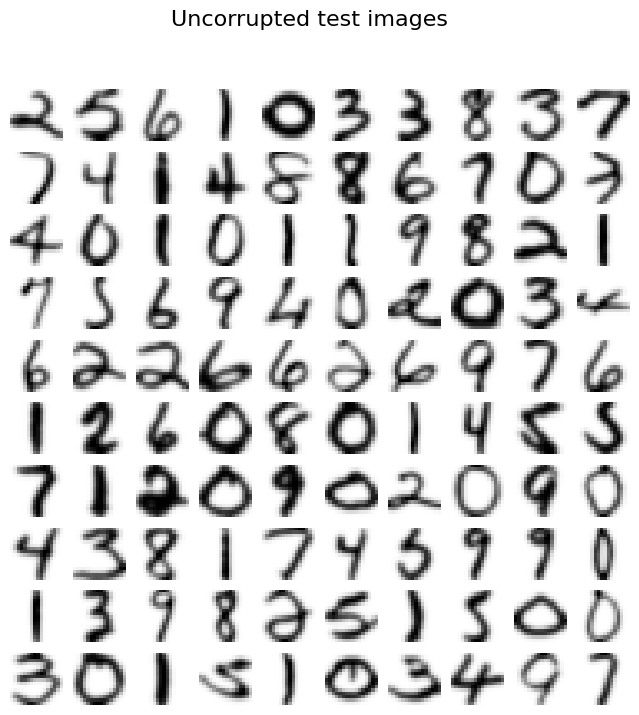

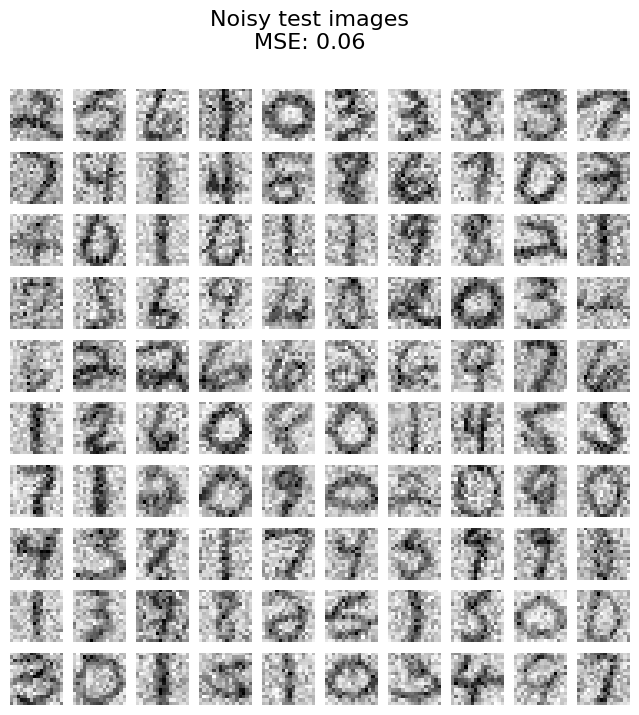

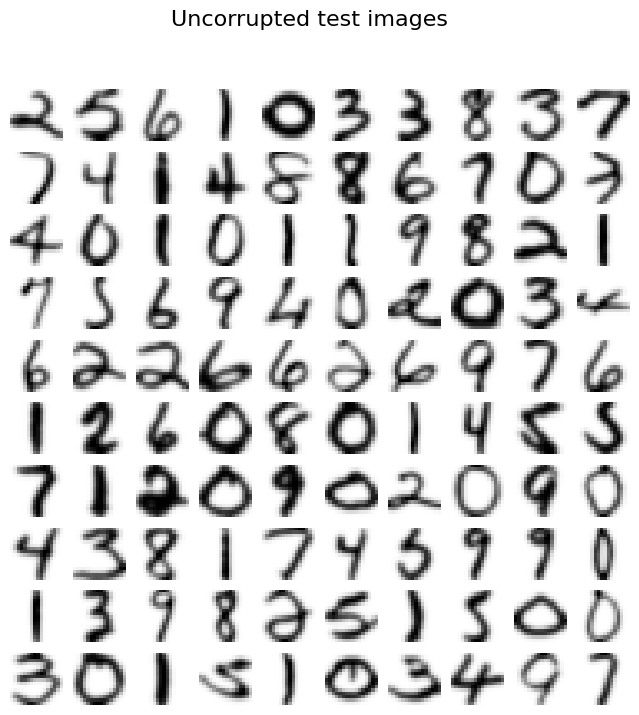

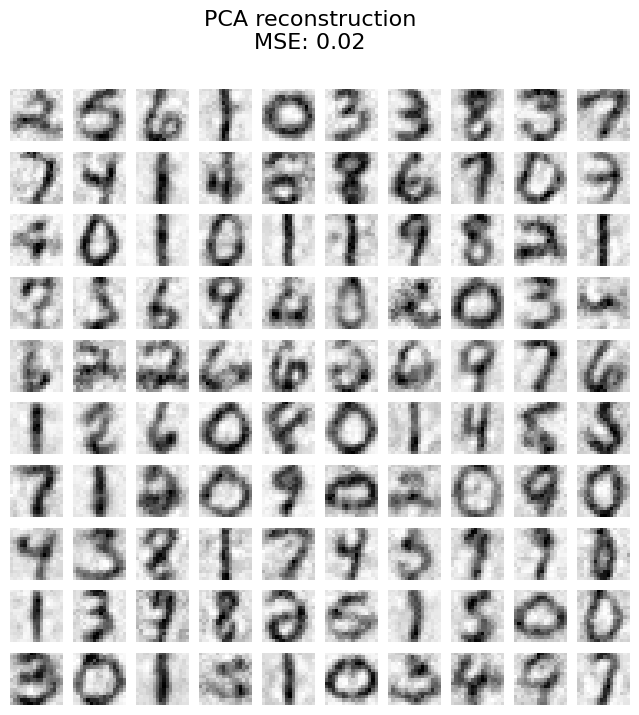

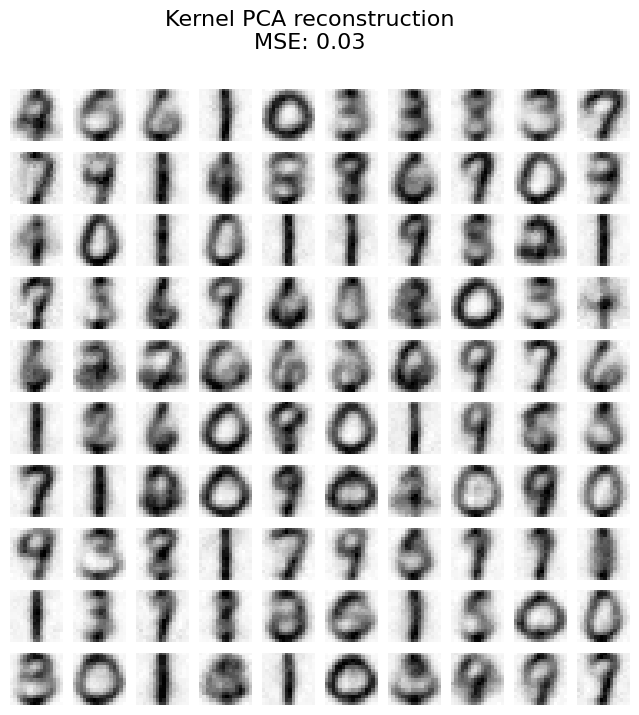

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA, KernelPCA

# -----------------------------
# 1. Wczytanie i przygotowanie danych
# -----------------------------
X, y = fetch_openml(data_id=41082, as_frame=False, return_X_y=True)
X = MinMaxScaler().fit_transform(X)

# -----------------------------
# 2. Podział na zbiór treningowy i testowy
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=0, train_size=1_000, test_size=100
)

# -----------------------------
# 3. Dodanie szumu
# -----------------------------
rng = np.random.RandomState(0)
X_train_noisy = X_train + rng.normal(scale=0.25, size=X_train.shape)
X_test_noisy = X_test + rng.normal(scale=0.25, size=X_test.shape)


# -----------------------------
# 4. Funkcja pomocnicza do wizualizacji obrazów
# -----------------------------
def plot_digits(X, title):
    """Wyświetla 100 obrazów w siatce 10x10."""
    fig, axs = plt.subplots(nrows=10, ncols=10, figsize=(8, 8))
    for img, ax in zip(X, axs.ravel()):
        ax.imshow(img.reshape((16, 16)), cmap="Greys")
        ax.axis("off")
    fig.suptitle(title, fontsize=16)
    plt.show()


# -----------------------------
# 5. Wyświetlenie przykładowych obrazów
# -----------------------------
plot_digits(X_test, "Uncorrupted test images")
mse_noisy = np.mean((X_test - X_test_noisy) ** 2)
plot_digits(X_test_noisy, f"Noisy test images\nMSE: {mse_noisy:.2f}")

# -----------------------------
# 6. Nauczenie PCA i Kernel PCA
# -----------------------------
pca = PCA(n_components=32, random_state=42)
kernel_pca = KernelPCA(
    n_components=400,
    kernel="rbf",
    gamma=1e-3,
    fit_inverse_transform=True,
    alpha=5e-3,
    random_state=42,
)

pca.fit(X_train_noisy)
kernel_pca.fit(X_train_noisy)

# -----------------------------
# 7. Rekonstrukcja obrazów testowych
# -----------------------------
X_reconstructed_pca = pca.inverse_transform(pca.transform(X_test_noisy))
X_reconstructed_kernel_pca = kernel_pca.inverse_transform(
    kernel_pca.transform(X_test_noisy)
)

# -----------------------------
# 8. Wyświetlenie wyników i MSE
# -----------------------------
plot_digits(X_test, "Uncorrupted test images")
plot_digits(
    X_reconstructed_pca,
    f"PCA reconstruction\nMSE: {np.mean((X_test - X_reconstructed_pca) ** 2):.2f}",
)
plot_digits(
    X_reconstructed_kernel_pca,
    f"Kernel PCA reconstruction\nMSE: {np.mean((X_test - X_reconstructed_kernel_pca) ** 2):.2f}",
)
